# Explore heuristic values for an empty maze

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## Create the maze representation

Define an empty $10 \times 10$ maze and place the start and goal. The figures retain one-based coordinate labels, while the NumPy array uses zero-based indices.

In [2]:
n = 10
start = np.array([1, 1])
goal = np.array([8, 8])

maze = np.full((n, n), " ", dtype=str)
maze[tuple(start)] = "S"
maze[tuple(goal)] = "G"
maze

array([[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', 'S', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', 'G', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']], dtype='<U1')

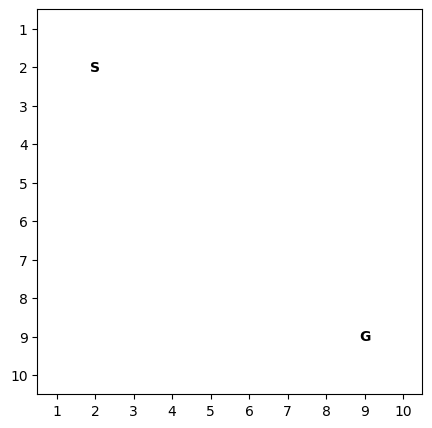

In [3]:
def show_values(values, cmap="YlOrRd_r", colorbar=True):
    """Display values on the maze and mark the start and goal."""
    figure, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(values, cmap=cmap, origin="upper")
    axis.set_xticks(range(n), labels=range(1, n + 1))
    axis.set_yticks(range(n), labels=range(1, n + 1))
    axis.text(goal[1], goal[0], "G", ha="center", va="center", fontweight="bold")
    axis.text(start[1], start[0], "S", ha="center", va="center", fontweight="bold")
    if colorbar:
        figure.colorbar(image, ax=axis, label="value")
    plt.show()


show_values(np.zeros((n, n)), cmap="Greys", colorbar=False)

## Greedy Best-First Search: Use Manhattan Distance for $h(n)$

Manhattan distance is also called the $L_1$ norm. It is the difference in x values plus the difference in y values: $L_1(a,b) = |a_x-b_x| + |a_y-b_y|$.

Manhattan distance is a perfect heuristic for the maze: $h(n) = h^*(n)$ and $f(n) = f^*(n)$ (the asterisk represents the optimal value). Calculate $h(n)$.

[[16 15 14 13 12 11 10  9  8  9]
 [15 14 13 12 11 10  9  8  7  8]
 [14 13 12 11 10  9  8  7  6  7]
 [13 12 11 10  9  8  7  6  5  6]
 [12 11 10  9  8  7  6  5  4  5]
 [11 10  9  8  7  6  5  4  3  4]
 [10  9  8  7  6  5  4  3  2  3]
 [ 9  8  7  6  5  4  3  2  1  2]
 [ 8  7  6  5  4  3  2  1  0  1]
 [ 9  8  7  6  5  4  3  2  1  2]]


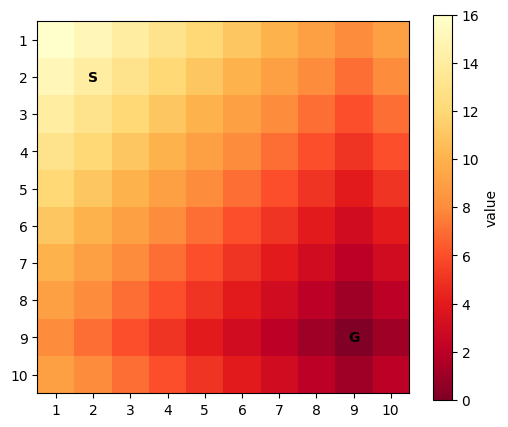

In [4]:
rows, columns = np.indices((n, n))
h_manhattan = np.abs(rows - goal[0]) + np.abs(columns - goal[1])
print(h_manhattan)
show_values(h_manhattan)

The algorithm will follow the color gradient from light yellow to dark red.

## A* with Manhattan heuristic

Calculate $f(n) = g(n) + h(n)$.

[[18 16 16 16 16 16 16 16 16 18]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [18 16 16 16 16 16 16 16 16 18]]


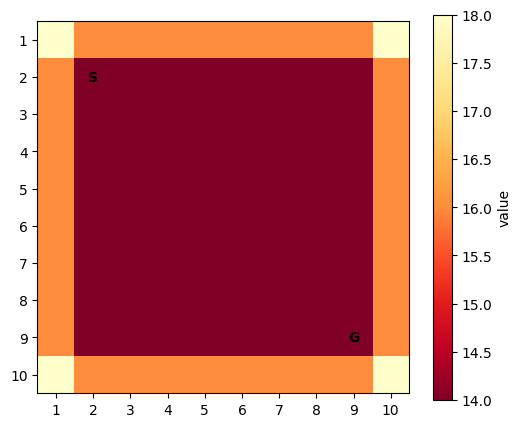

In [5]:
g = np.abs(rows - start[0]) + np.abs(columns - start[1])
f = g + h_manhattan
print(f)
show_values(f)

**Note:** In Manhattan geometry, all paths that go directly from $S$ to $G$ are optimal and have the same distance. Even with a perfect heuristic, the agent faces a plateau of positions with exactly the same $f(n) = C^*$. All directions are tied, so the tie-breaking strategy is important. For A* search with a reached data structure, this means that all states in the red square will be explored leading to very inefficient search!

[Amit Patel's discussion of heuristics](http://theory.stanford.edu/~amitp/GameProgramming/Heuristics.html) describes this and other issues and suggests increasing the value of $h(n)$ by a small factor, leading to weighted A* search.

## Weighted A* Search

Use $f(n) = g(n) + W \times h(n)$, with $W > 0$. For $W>1$, this is not guaranteed to be optimal because the weighted heuristic may become inadmissible, but it can reduce search time and memory. First, inflate the heuristic by 10%.

[[19.6 17.5 17.4 17.3 17.2 17.1 17.  16.9 16.8 18.9]
 [17.5 15.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 16.8]
 [17.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 16.7]
 [17.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 16.6]
 [17.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 16.5]
 [17.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 16.4]
 [17.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 16.3]
 [16.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 16.2]
 [16.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 14.  16.1]
 [18.9 16.8 16.7 16.6 16.5 16.4 16.3 16.2 16.1 18.2]]


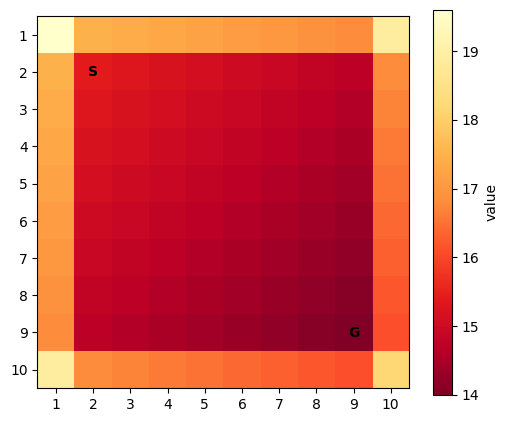

In [6]:
f = g + 1.10 * h_manhattan
print(f)
show_values(f)

The weighting create a slight gradient that leads directly from $S$ to $G$. Now try $W=5$. As $W$ increases, weighted A* approaches greedy best-first search (GBFS), which completely ignores $g(n)$.

[[82 76 72 68 64 60 56 52 48 54]
 [76 70 66 62 58 54 50 46 42 48]
 [72 66 62 58 54 50 46 42 38 44]
 [68 62 58 54 50 46 42 38 34 40]
 [64 58 54 50 46 42 38 34 30 36]
 [60 54 50 46 42 38 34 30 26 32]
 [56 50 46 42 38 34 30 26 22 28]
 [52 46 42 38 34 30 26 22 18 24]
 [48 42 38 34 30 26 22 18 14 20]
 [54 48 44 40 36 32 28 24 20 26]]


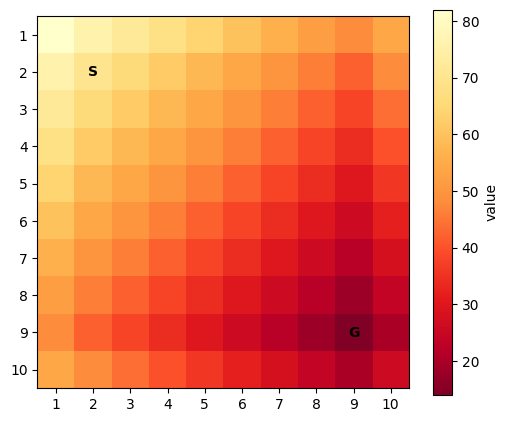

In [7]:
f = g + 5 * h_manhattan
print(f)
show_values(f)

Using $W<1$ makes the search behave more like uniform-cost search (BFS when every step has the same cost). This leads to exploring the area around $S$ first and very inefficient search.

[[10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [ 8.5  7.   7.5  8.   8.5  9.   9.5 10.  10.5 12. ]
 [ 9.   7.5  8.   8.5  9.   9.5 10.  10.5 11.  12.5]
 [ 9.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 13. ]
 [10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [10.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 14. ]
 [11.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  14.5]
 [11.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 15. ]
 [12.  10.5 11.  11.5 12.  12.5 13.  13.5 14.  15.5]
 [13.5 12.  12.5 13.  13.5 14.  14.5 15.  15.5 17. ]]


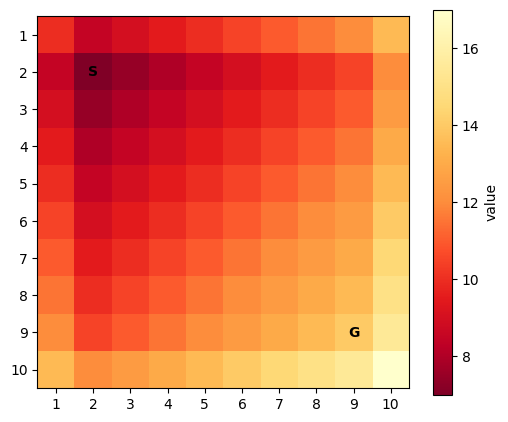

In [8]:
f = g + 0.5 * h_manhattan
print(f)
show_values(f)

## Greedy Best-First Search with Euclidean Distance for $h(n)$

Euclidean distance is the $L_2$ norm: $L_2(a,b) = \sqrt{(a_x-b_x)^2 + (a_y-b_y)^2}$. It is not perfect when the true cost follows Manhattan distance, but it is admissible: $h(n) \leq h^*(n)$.

[[11.3137 10.6301 10.      9.434   8.9443  8.544   8.2462  8.0623  8.
   8.0623]
 [10.6301  9.8995  9.2195  8.6023  8.0623  7.6158  7.2801  7.0711  7.
   7.0711]
 [10.      9.2195  8.4853  7.8102  7.2111  6.7082  6.3246  6.0828  6.
   6.0828]
 [ 9.434   8.6023  7.8102  7.0711  6.4031  5.831   5.3852  5.099   5.
   5.099 ]
 [ 8.9443  8.0623  7.2111  6.4031  5.6569  5.      4.4721  4.1231  4.
   4.1231]
 [ 8.544   7.6158  6.7082  5.831   5.      4.2426  3.6056  3.1623  3.
   3.1623]
 [ 8.2462  7.2801  6.3246  5.3852  4.4721  3.6056  2.8284  2.2361  2.
   2.2361]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]
 [ 8.      7.      6.      5.      4.      3.      2.      1.      0.
   1.    ]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]]


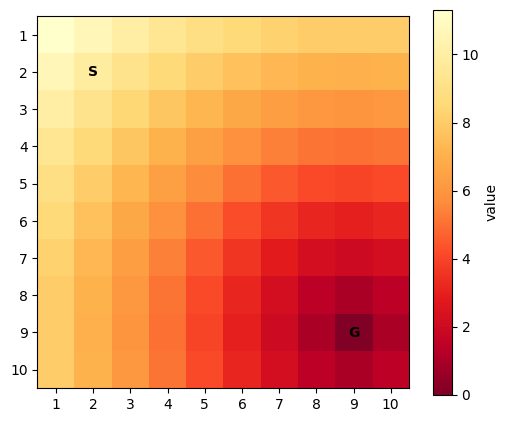

In [9]:
h_euclidean = np.hypot(rows - goal[0], columns - goal[1])
print(h_euclidean)
show_values(h_euclidean)

## A* with Euclidean Distance for $h(n)$

[[13.3137 11.6301 12.     12.434  12.9443 13.544  14.2462 15.0623 16.
  17.0623]
 [11.6301  9.8995 10.2195 10.6023 11.0623 11.6158 12.2801 13.0711 14.
  15.0711]
 [12.     10.2195 10.4853 10.8102 11.2111 11.7082 12.3246 13.0828 14.
  15.0828]
 [12.434  10.6023 10.8102 11.0711 11.4031 11.831  12.3852 13.099  14.
  15.099 ]
 [12.9443 11.0623 11.2111 11.4031 11.6569 12.     12.4721 13.1231 14.
  15.1231]
 [13.544  11.6158 11.7082 11.831  12.     12.2426 12.6056 13.1623 14.
  15.1623]
 [14.2462 12.2801 12.3246 12.3852 12.4721 12.6056 12.8284 13.2361 14.
  15.2361]
 [15.0623 13.0711 13.0828 13.099  13.1231 13.1623 13.2361 13.4142 14.
  15.4142]
 [16.     14.     14.     14.     14.     14.     14.     14.     14.
  16.    ]
 [17.0623 15.0711 15.0828 15.099  15.1231 15.1623 15.2361 15.4142 16.
  17.4142]]


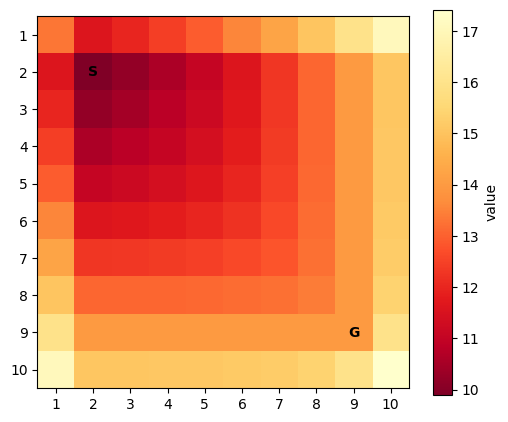

In [10]:
f = g + h_euclidean
print(f)
show_values(f)

**Note:** Euclidean and Manhattan geometry do not mix well here; the gradient is actually from the goal toward the start.
          A* expands every node with $f(n)<C^*$ and some nodes with $f(n)=C^*$. These nodes are shown in black below.

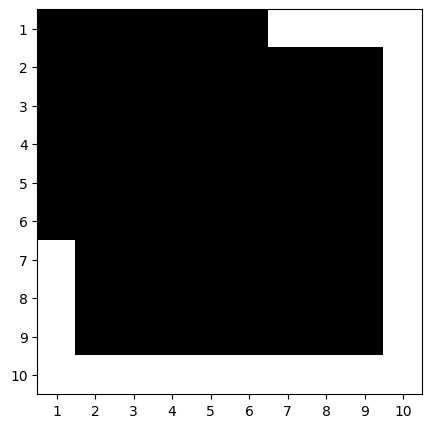

In [11]:
optimal_cost = f[tuple(goal)]
show_values(f <= optimal_cost, cmap="Greys", colorbar=False)

# Conclusion

We need to be careful when choosing heuristics to make sure that we still create a clear gradient for A* to follow. Otherwise, we will end up with an algorithm that is as inefficient as BFS. 

# Bài 6 – Bài làm (chạy code)
Các hàm GBFS, A*, Weighted A*, BFS nằm trong `tree_search_solution.py` (cùng thư mục, đọc các file `*.txt` bằng đường dẫn tương đối).

In [12]:
import sys; sys.path.insert(0, ".")
import tree_search_solution as ts
from maze_helper import parse_maze
files = {'small':'small_maze.txt','medium':'medium_maze.txt','large':'large_maze.txt','open':'open_maze.txt',
         'L':'L_maze.txt','loops':'loops_maze.txt','empty':'empty_maze.txt','empty_2':'empty_maze_2.txt'}
mazes = {k: parse_maze(open(v).read()) for k, v in files.items()}
print("Đã đọc", len(mazes), "mê cung")

Đã đọc 8 mê cung


## 6.1 Số ô có f(n) ≤ C* và so sánh Manhattan / Euclidean trong mê cung rỗng 10×10
A* mở rộng mọi nút có f(n) < C* và một số nút có f(n) = C*.

In [13]:
C_star = 14
rows, cols = np.indices((n, n)); g_ = np.abs(rows-start[0]) + np.abs(cols-start[1])
fm = g_ + np.abs(rows-goal[0]) + np.abs(cols-goal[1]); fe = g_ + np.hypot(rows-goal[0], cols-goal[1])
print("Số ô có f(n) <= C* :  Manhattan =", int((fm <= C_star).sum()), "|  Euclidean =", int((fe <= C_star + 1e-9).sum()), "(trên 100 ô)")

m10 = np.full((n, n), " ", dtype=str); m10[tuple(start)] = "S"; m10[tuple(goal)] = "G"
print("\nBFS:", {k: v for k, v in ts.bfs(m10).items() if k != 'time'})
print(f"\n{'thuật toán':9}{'heuristic':11}{'cost':>5}{'nút (FIFO)':>12}{'nút (LIFO)':>12}{'max frontier':>14}")
for kind, h in [('gbfs','manhattan'),('gbfs','euclid'),('astar','manhattan'),('astar','euclid'),('astar','chebyshev')]:
    a = ts.best_first(m10, kind, h); l = ts.best_first(m10, kind, h, tie='lifo')
    print(f"{kind:9}{h:11}{a['cost']:>5}{a['exp']:>12}{l['exp']:>12}{a['maxfr']:>14}")

Số ô có f(n) <= C* :  Manhattan = 64 |  Euclidean = 75 (trên 100 ô)

BFS: {'cost': 14, 'exp': 95, 'maxfr': 12}

thuật toánheuristic   cost  nút (FIFO)  nút (LIFO)  max frontier
gbfs     manhattan     14          14          14            29
gbfs     euclid        14          14          14            18
astar    manhattan     14          63          14            31
astar    euclid        14          74          61            21
astar    chebyshev     14          76          67            19


**Nhận xét.** Với A* + Manhattan, cả hình chữ nhật 8×8 giữa S và G có f = 14 = C* (cao nguyên các nút bằng nhau): chỉ đổi cách phá hòa FIFO → LIFO số nút mở rộng giảm từ 63 xuống 14. Euclidean có 75/100 ô thỏa f ≤ C* (Manhattan: 64) nên A* khảo sát vùng lớn hơn (74 nút so với 63). GBFS với cả hai heuristic đều đi thẳng 14 nút.

## 6.2 Weighted A* (Manhattan) – thay đổi trọng số w

In [14]:
print(f"{'w':>5}{'cost':>6}{'nút (FIFO)':>12}{'nút (LIFO)':>12}")
for w in [0.5, 1.0, 1.1, 1.5, 2, 5]:
    a = ts.best_first(m10, 'astar', 'manhattan', w=w); l = ts.best_first(m10, 'astar', 'manhattan', w=w, tie='lifo')
    print(f"{w:>5}{a['cost']:>6}{a['exp']:>12}{l['exp']:>12}")

    w  cost  nút (FIFO)  nút (LIFO)
  0.5    14          92          90
  1.0    14          63          14
  1.1    14          14          14
  1.5    14          14          14
    2    14          14          14
    5    14          14          14


**Nhận xét.** w < 1: thuật toán giống BFS/UCS (mở rộng quanh S). w = 1,1 đã tạo gradient chỉ thẳng từ S tới G (63 → 14 nút). w lớn dần tiến tới GBFS (bỏ qua g); với w > 1 chỉ còn đảm bảo chi phí ≤ w·C*.

## 6.3 Các mê cung của bài tập: GBFS và A* với Manhattan / Euclidean
Định dạng ô: path cost / nút mở rộng / max frontier.

In [15]:
print(f"{'maze':8}{'BFS':>16}{'GBFS-Man':>16}{'GBFS-Euc':>16}{'A*-Man':>16}{'A*-Euc':>16}")
for name, mz in mazes.items():
    row = [ts.bfs(mz)] + [ts.best_first(mz, k, h) for k, h in [('gbfs','manhattan'),('gbfs','euclid'),('astar','manhattan'),('astar','euclid')]]
    print(f"{name:8}" + "".join(f"{r['cost']:>5}/{r['exp']:>4}/{r['maxfr']:>3} " for r in row))

maze                 BFS        GBFS-Man        GBFS-Euc          A*-Man          A*-Euc
small      19/  92/  9    29/  39/  5    29/  39/  5    19/  53/  8    19/  56/  7 
medium     68/ 269/  9    74/  78/  4   152/ 159/  8    68/ 221/  8    68/ 226/  8 
large     210/ 621/  8   210/ 466/ 21   210/ 471/ 21   210/ 549/ 12   210/ 557/ 10 
open       54/ 682/ 25    68/  89/ 66    54/  54/ 62    54/ 535/ 25    54/ 550/ 51 
L          16/ 151/ 17    20/  46/ 25    18/  39/ 24    16/  53/ 26    16/  70/ 29 
loops      23/  71/  8    23/  67/ 10    23/  64/ 10    23/  58/  6    23/  64/ 10 
empty      14/  95/ 12    14/  14/ 29    14/  14/ 18    14/  63/ 31    14/  74/ 21 
empty_2    14/  95/ 11    14/  14/ 29    14/  14/ 18    14/  63/ 31    14/  74/ 21 


**Nhận xét.**
* A* (cả hai heuristic) luôn cho đường tối ưu; GBFS ít nút nhất nhưng không tối ưu (small 29 vs 19; medium 74 và 152 vs 68; open 68 vs 54; L 20 và 18 vs 16).
* Với A*, Manhattan mở rộng ít hơn hoặc bằng Euclidean ở cả 7 mê cung (L: 53 vs 70; empty: 63 vs 74).
* Với GBFS, Manhattan không luôn tốt hơn (open: Euclid 54 tốt hơn Manhattan 68) vì GBFS chỉ nhìn h(n), không có bảo đảm gì.
* Trong mê cung nhiều tường (large chỉ có một đường đi) heuristic chỉ giảm nhẹ so với BFS (549 vs 621 nút).

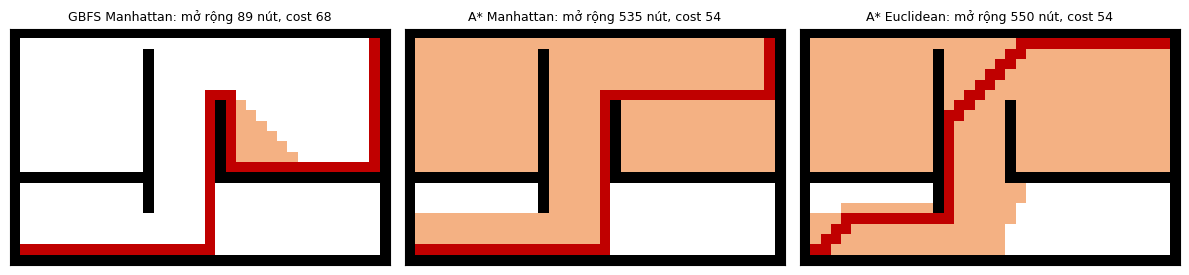

In [16]:
import matplotlib.pyplot as plt
from matplotlib import colors
mz = mazes['open']; fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, (kind, h, t) in zip(ax, [('gbfs','manhattan','GBFS Manhattan'),('astar','manhattan','A* Manhattan'),('astar','euclid','A* Euclidean')]):
    r = ts.best_first(mz, kind, h); v = np.zeros(mz.shape); v[mz == 'X'] = -1
    for p in r['order']: v[p] = 1
    for p in r['path']: v[p] = 2
    a.imshow(v, cmap=colors.ListedColormap(['black','white','#f4b183','#c00000']), vmin=-1, vmax=2)
    a.set_title(f"{t}: mở rộng {r['exp']} nút, cost {r['cost']}", fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 6.4 Vì sao Manhattan hợp với lưới 4 hướng hơn Euclidean?
* Chi phí thật trên lưới trống bằng |Δx| + |Δy| nên Manhattan là hoàn hảo (h = h*) khi không có tường và vẫn là cận dưới khi có tường.
* Euclid chỉ là cận dưới yếu: √(Δx²+Δy²) ≤ |Δx|+|Δy| (còn ≈ 71% theo đường chéo) → nhiều nút có f < C* phải mở rộng.
* g(n) đếm bước theo Manhattan còn h(n) theo Euclid nên f bị méo, gradient chạy ngược từ G về S (xem bản đồ f ở trên).

## 6.5 Heuristic đề xuất: Chebyshev, h(n) = max(|Δx|, |Δy|)
Kiểm tra bằng thực nghiệm tính **admissible** (h ≤ h*) và **consistent** (h(n) ≤ c + h(n')) trên mọi ô của mọi mê cung, với h* là khoảng cách thật tính bằng BFS ngược từ G.

In [17]:
from collections import deque
def true_dist(mz):
    goal = ts.find_pos(mz, 'G'); d = {goal: 0}; q = deque([goal])
    while q:
        p = q.popleft()
        for _, nb in ts._neighbors(mz, p, "NESW"):
            if nb not in d: d[nb] = d[p] + 1; q.append(nb)
    return d, goal
print(f"{'maze':8}{'heuristic':11}{'admissible':>12}{'consistent':>12}")
for name, mz in mazes.items():
    d, goal = true_dist(mz)
    for h in ('manhattan', 'euclid', 'chebyshev'):
        hf = ts.H[h]
        adm = all(hf(p, goal) <= d[p] + 1e-9 for p in d)
        con = all(hf(p, goal) <= 1 + hf(q, goal) + 1e-9 for p in d for _, q in ts._neighbors(mz, p, "NESW"))
        print(f"{name:8}{h:11}{str(adm):>12}{str(con):>12}")

maze    heuristic    admissible  consistent
small   manhattan          True        True
small   euclid             True        True
small   chebyshev          True        True
medium  manhattan          True        True
medium  euclid             True        True
medium  chebyshev          True        True
large   manhattan          True        True
large   euclid             True        True
large   chebyshev          True        True
open    manhattan          True        True
open    euclid             True        True
open    chebyshev          True        True
L       manhattan          True        True
L       euclid             True        True
L       chebyshev          True        True
loops   manhattan          True        True
loops   euclid             True        True
loops   chebyshev          True        True
empty   manhattan          True        True
empty   euclid             True        True
empty   chebyshev          True        True
empty_2 manhattan          True 

In [18]:
print(f"{'maze':8}" + "".join(f"{h:>22}" for h in ('manhattan','euclid','chebyshev')) + "   (cost / nút mở rộng)")
for name, mz in mazes.items():
    rs = [ts.best_first(mz, 'astar', h) for h in ('manhattan','euclid','chebyshev')]
    print(f"{name:8}" + "".join(f"{r['cost']:>14}/{r['exp']:>4}      " for r in rs))

maze                 manhattan                euclid             chebyshev   (cost / nút mở rộng)
small               19/  53                  19/  56                  19/  56      
medium              68/ 221                  68/ 226                  68/ 228      
large              210/ 549                 210/ 557                 210/ 578      


open                54/ 535                  54/ 550                  54/ 568      
L                   16/  53                  16/  70                  16/  88      
loops               23/  58                  23/  64                  23/  66      
empty               14/  63                  14/  74                  14/  76      
empty_2             14/  63                  14/  74                  14/  76      


**Kết luận Bài 6.**
* Chebyshev vẫn admissible và consistent (max(a,b) ≤ a+b ≤ h*), nên A* + Chebyshev vẫn tối ưu, nhưng yếu hơn Manhattan nên mở rộng nhiều nút hơn.
* **Điều kiện để A* tối ưu:** h(n) ≤ h*(n) và h(goal) = 0 (admissible) cho tìm kiếm trên cây; với bảng reached/closed cần thêm h(n) ≤ c(n,n') + h(n') (consistent). Nhân h với w > 1 làm mất bảo đảm (chỉ còn ≤ w·C*).
* Heuristic mạnh hơn nữa: khoảng cách thật tính bằng BFS ngược từ G (h = h*), đổi lại tốn một lần duyệt toàn mê cung.
* Cách phá hòa (tie-breaking) cũng quan trọng không kém chất lượng heuristic: A* + Manhattan trong mê cung rỗng từ 63 xuống 14 nút khi đổi FIFO → LIFO.